<a href="https://colab.research.google.com/github/advayvyas/OptimalRidge/blob/colab/algorithm_tests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Full algorithm tests

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.optimize import minimize_scalar
from time import perf_counter
import warnings

## GCV Functions

### Data generation functions

In [2]:
def spiked_covariance(D):
    """
    Spiked-type covariance eigenvalues.

    Args:
        D: the number of parameters in the data matrix

    Returns:
        Sigma: the covariance matrix
    """
    x = np.linspace(-3, 3, D)
    eigenvalues = norm.pdf(x)
    eigenvalues = eigenvalues / eigenvalues.max()
    Sigma = np.diag(eigenvalues)
    return Sigma

def bulk_covariance(D):
    """
    Bulk-type covariance eigenvalues

    Args:
        D: the number of parameters in the data matrix

    Returns:
        Sigma: the covariance matrix
    """

    j = np.arange(1, D + 1)
    eigenvalues = (D - j + 1) / D
    Sigma = np.diag(eigenvalues)

    return Sigma

def generate_X(N, D, Sigma, rng):
    """
    Generates a random X (without sample centering) from a multivariate normal distribution.

    Args:
        N: the number of observations.
        D: the number of parameters.
        Sigma: the covariance matrix of the data matrix
            X with shape DxD.
        rng: A NumPy random number generator

    Returns:
        A matrix X of the shape NxD (N rows, D columns).
    """
    mu = np.zeros(D)
    X = rng.multivariate_normal(mean=mu, cov=Sigma, size=N)
    return X


def generate_Y(X, N, theta, epsilon, rng):
    """
    Generates a response y with Gaussian noise (without sample centering).

    Args:
        X: the data matrix with shape NxD.
        N: the number of observations.
        theta: the true parameter vector.
        epsilon: the noise amplitude.
        rng: A NumPy random number generator

    Returns:
        A column vector y of the shape Nx1 (N rows, 1 column).
    """
    z = (rng.standard_normal(size=N))[:, np.newaxis]
    y = X @ theta + epsilon * z
    return y

### GCV and its offshoot functions

In [3]:
def G(lam, n, a, singular_values):
    a = np.asarray(a).reshape(-1)
    s2 = np.asarray(singular_values).reshape(-1)**2
    m = len(s2)
    d = s2 + lam

    if m == n:
        w = 1 / d
        w /= w.sum()
        return n * np.sum((a[:m] * w)**2)

    residual_weights = lam / d

    numerator = (
        np.sum((residual_weights * a[:m])**2)
        + np.sum(a[m:]**2)
    )

    denominator = (
        (n - m) + np.sum(residual_weights)
    )**2

    return n * numerator / denominator

\begin{equation}
    A(\lambda) = \left[
    \displaystyle\sum_{j=1}^m
    \frac{\lambda^2 a_j^2}{n(\sigma_j^2+\lambda)^2}
    +\displaystyle\sum_{j=m+1}^n\frac{a_j^2}{n}
    \right]
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^2}
    \right]
\end{equation}

\begin{equation}
    B(\lambda) = \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2 a_j^2}{(\sigma_j^2+\lambda)^3} \left[1-\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{\sigma_j^2+\lambda}\right]
\end{equation}

\begin{equation}
    A'(\lambda) = \left[\frac{2\lambda}{n} \sum_{j = 1}^m \frac{\sigma_j^2 a_j^2}{(\sigma_j^2 + \lambda)^3}
    \right]
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^2}
    \right] -2 \left[
    \displaystyle\sum_{j=1}^m
    \frac{\lambda^2 a_j^2}{n(\sigma_j^2+\lambda)^2}
    +\displaystyle\sum_{j=m+1}^n\frac{a_j^2}{n}
    \right]
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^3}
    \right]
\end{equation}

\begin{equation}
    B'(\lambda) = -3\left[\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2 a_j^2}{(\sigma_j^2+\lambda)^4} \right]\left[1-\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{\sigma_j^2+\lambda}\right] + \left[\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2 a_j^2}{(\sigma_j^2+\lambda)^3} \right]\left[\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^2}\right].
\end{equation}

In [4]:
def A(lam, n, a, singular_values):
    a = np.asarray(a, dtype=float).reshape(-1)
    s2 = np.asarray(singular_values, dtype=float)**2
    m = len(s2)
    d = s2 + lam

    residual = (
        np.sum((lam**2 * a[:m]**2) / d**2)
        + np.sum(a[m:]**2)
    ) / n

    return residual * np.sum(s2 / d**2)


def B(lam, n, a, singular_values):
    a = np.asarray(a, dtype=float).reshape(-1)
    s2 = np.asarray(singular_values, dtype=float)**2
    m = len(s2)
    d = s2 + lam

    weighted_sum = np.sum((s2 * a[:m]**2) / d**3)
    factor = ((n - m) + np.sum(lam / d)) / n

    return weighted_sum * factor


def A_prime(lam, n, a, singular_values):
    a = np.asarray(a, dtype=float).reshape(-1)
    s2 = np.asarray(singular_values, dtype=float)**2
    m = len(s2)
    d = s2 + lam

    residual = (
        np.sum((lam**2 * a[:m]**2) / d**2)
        + np.sum(a[m:]**2)
    ) / n

    residual_prime = (2 * lam / n) * np.sum(
        (s2 * a[:m]**2) / d**3
    )

    return (
        (residual_prime * np.sum(s2 / d**2))
        - (2 * residual * np.sum(s2 / d**3))
    )


def B_prime(lam, n, a, singular_values):
    a = np.asarray(a, dtype=float).reshape(-1)
    s2 = np.asarray(singular_values, dtype=float)**2
    m = len(s2)
    d = s2 + lam

    weighted_sum = np.sum((s2 * a[:m]**2) / d**3)
    weighted_sum_prime = -3 * np.sum((s2 * a[:m]**2) / d**4)
    factor = ((n - m) + np.sum(lam / d)) / n
    factor_prime = np.sum(s2 / d**2) / n

    return weighted_sum_prime * factor + weighted_sum * factor_prime

\begin{equation}
    G'(\lambda) =
    \frac{
    \dfrac{2\lambda}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2 a_j^2}{(\sigma_j^2+\lambda)^3}
    }{
    \left[1-\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{\sigma_j^2+\lambda}\right]^2
    }
    - \frac{
    \dfrac{2}{n}
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\lambda^2 a_j^2}{n(\sigma_j^2+\lambda)^2}
    +\displaystyle\sum_{j=m+1}^n\frac{a_j^2}{n}
    \right]
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^2}
    \right]
    }{
    \left[1-\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{\sigma_j^2+\lambda}\right]^3
    },
\end{equation}

In [5]:
def Gprime(lam, n, a, singular_values):
    a = np.asarray(a, dtype=float).reshape(-1)
    s2 = np.asarray(singular_values, dtype=float).reshape(-1)**2
    m = len(s2)
    d = s2 + lam

    residual = (
        np.sum((lam**2 * a[:m]**2) / d**2)
        + np.sum(a[m:n]**2)
    ) / n

    residual_prime = (2 * lam / n) * np.sum(
        (s2 * a[:m]**2) / d**3
    )

    denominator = ((n - m) + np.sum(lam / d)) / n

    return (
        residual_prime / ((denominator)**2)
        - ((2 / n) * residual * np.sum(s2 / d**2)) / ((denominator)**3)
    )

\begin{equation}
    \lambda
    = \frac{\left[
    \displaystyle\sum_{j=1}^m
    \frac{\lambda^2 a_j^2}{n(\sigma_j^2+\lambda)^2}
    +\displaystyle\sum_{j=m+1}^n\frac{a_j^2}{n}
    \right]
    \left[
    \displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{(\sigma_j^2+\lambda)^2}
    \right]}{\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2 a_j^2}{(\sigma_j^2+\lambda)^3} \left[1-\dfrac{1}{n}\displaystyle\sum_{j=1}^m
    \frac{\sigma_j^2}{\sigma_j^2+\lambda}\right]} = H(\lambda)
\end{equation}

\begin{equation}
    H'(\lambda) = \dfrac{A'(\lambda)}{B(\lambda)} - \dfrac{A(\lambda)B'(\lambda)}{(B(\lambda))^2}
\end{equation}

$$F(\lambda) = \frac{\lambda + H(\lambda)}{2}$$

$$F'(\lambda) = \dfrac{d}{d\lambda} \left[ \frac{\lambda + H(\lambda)}{2} \right] = \frac{1 + H'(\lambda)}{2}$$

\begin{equation}
    F'(\lambda) = \dfrac{1}{2} \left[1 +  \dfrac{A'(\lambda)}{B(\lambda)} - \dfrac{A(\lambda)B'(\lambda)}{(B(\lambda))^2} \right].
\end{equation}



In [6]:
def H(lam, n, a, singular_values):
    A_val = A(lam, n, a, singular_values)
    B_val = B(lam, n, a, singular_values)

    if B_val == 0:
        raise ZeroDivisionError("H is undefined when B(lam) = 0.")

    return A_val / B_val


def H_prime(lam, n, a, singular_values):
    A_val = A(lam, n, a, singular_values)
    B_val = B(lam, n, a, singular_values)

    if B_val == 0:
        raise ZeroDivisionError("H_prime is undefined when B(lam) = 0.")

    Ap_val = A_prime(lam, n, a, singular_values)
    Bp_val = B_prime(lam, n, a, singular_values)

    return Ap_val / B_val - A_val * Bp_val / B_val**2

def F(lam, n, a, singular_values):
    return (lam + H(lam, n, a, singular_values)) / 2

def F_prime(lam, n, a, singular_values):
    return (1 + H_prime(lam, n, a, singular_values)) / 2


### Relaxation parameter implementation

In [7]:
# Changing these to work with an alpha relaxation parameter

# n_alpha = 1000
# alpha = ((2*n_alpha)-1)/(3 * n_alpha)

# def F(lam, n, a, singular_values):
#     return ( (1-alpha) * lam + (alpha) * H(lam, n, a, singular_values) )

# def F_prime(lam, n, a, singular_values):
#     return ( (1-alpha) + (alpha) * H_prime(lam, n, a, singular_values) )

### Level-set function

In [8]:
def fprime_levelsets(lam_max, steps, n, a, singular_values):
    def root_finder(lam):
        return abs(F_prime(lam, n, a, singular_values)) - 1

    lam_grid = np.linspace(0, lam_max, steps)[1:]
    values = np.array([root_finder(lam) for lam in lam_grid])
    roots = []

    if not np.all(np.isfinite(values)):
        raise ValueError("Nonfinite derivative values in the search range.")

    for i in range(len(lam_grid) - 1):
        if values[i] == 0:
            roots.append(lam_grid[i])

        if values[i] * values[i + 1] < 0:
            roots.append(brentq(root_finder, lam_grid[i], lam_grid[i + 1]))

    edges = sorted(set([0, *roots, lam_max]))

    endpoints = []
    for left, right in zip(edges[:-1], edges[1:]):
        if root_finder((left + right) / 2) < 0:
            endpoints.extend([left, right])

    return endpoints

### Fixed-point iteration functions

In [9]:
def create_intervals(endpoints):
  if len(endpoints) % 2 != 0:
    raise ValueError("The list of endpoints must be even.")

  intervals = []
  for i in range(0, len(endpoints), 2):
    intervals.append((endpoints[i], endpoints[i + 1]))

  return intervals

In [10]:
def fixed_point_iteration(lam_0, n, a, singular_values, iterations=10000, tol=1e-8):
    """Iterate the existing F and record each accepted update (iteration 0 is the start).

    Convergence means the lambda step meets the tolerance, not global optimality.
    elapsed_seconds measures this run only, excluding the SVD and interval search.
    """
    if not np.isfinite(lam_0) or lam_0 <= 0:
        raise ValueError("lam_0 must be finite and positive.")
    if not isinstance(iterations, (int, np.integer)) or iterations < 0:
        raise ValueError("iterations must be a nonnegative integer.")
    if not np.isfinite(tol) or tol <= 0:
        raise ValueError("tol must be finite and positive.")

    current_lam = float(lam_0)
    current_gcv = float(G(current_lam, n, a, singular_values))
    if not np.isfinite(current_gcv):
        raise ValueError("The initial GCV is not finite.")
    lambdas, gcvs, times = [current_lam], [current_gcv], [0.0]
    best_lambdas, best_gcvs = [current_lam], [current_gcv]
    converged, status = False, "max_iter"
    started = perf_counter()

    for _ in range(iterations):
        try:
            with np.errstate(over="raise", divide="raise", invalid="raise"):
                next_lam = float(F(current_lam, n, a, singular_values))
                if not np.isfinite(next_lam) or next_lam <= 0:
                    status = "invalid_lambda"
                    break
                next_gcv = float(G(next_lam, n, a, singular_values))
        except (FloatingPointError, ZeroDivisionError):
            status = "numerical_failure"
            break
        if not np.isfinite(next_gcv):
            status = "nonfinite_gcv"
            break

        lambdas.append(next_lam)
        gcvs.append(next_gcv)
        times.append(perf_counter() - started)
        improved = next_gcv < best_gcvs[-1]
        best_lambdas.append(next_lam if improved else best_lambdas[-1])
        best_gcvs.append(next_gcv if improved else best_gcvs[-1])
        step = abs(next_lam - current_lam)
        threshold = tol * (1 + abs(current_lam))
        current_lam = next_lam
        if step <= threshold:
            converged, status = True, "converged"
            break

    return {
        "lambda_0": float(lam_0),
        "lambda_star": lambdas[-1], "gcv_star": gcvs[-1],
        "n_iter": len(lambdas) - 1 if converged else -1,
        "steps_completed": len(lambdas) - 1,
        "converged": converged, "status": status,
        "history": {
            "iteration": np.arange(len(lambdas)),
            "lambda": np.asarray(lambdas), "gcv": np.asarray(gcvs),
            "best_lambda": np.asarray(best_lambdas),
            "best_gcv": np.asarray(best_gcvs),
            "elapsed_seconds": np.asarray(times),
        },
    }

## Full GCV contraction algorithm function

In [11]:
def gcv_contraction(X, y, lam_max=None, steps=1000, max_iter=10000,
                    tol=1e-8, initial_lambdas=None, max_starts=1000, verbose=True):
    """Run GCV fixed-point searches on one dataset using G, F and the level sets.

    Default starts follow the original construction: scan |F'| < 1, set
    r_hat to half the narrowest detected interval width, and use midpoints
    of bins of width 2*r_hat over [0, lam_max] (clipping the final bin).
    lam_max defaults to the largest squared singular value, NOT a known optimum.
    It limits the search for starts, not the subsequent fixed-point iterates.
    Explicit initial_lambdas skip interval detection.

    Returns a dict with the selected lambda_star/gcv_star, n_iter for that
    run, total_iterations across all runs, and runs containing every history.
    Select the lowest final GCV among converged runs. If none converged,
    return the lowest final GCV with converged=False; inspect status/history.
    best_lambda/best_gcv separately report the best point visited by any run.
    The grid scan and fixed-point convergence do not certify global optimality.
    """
    started = perf_counter()
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim != 2 or min(X.shape) == 0:
        raise ValueError("X must be a nonempty two-dimensional matrix.")
    if y.ndim not in (1, 2) or (y.ndim == 2 and y.shape[1] != 1):
        raise ValueError("y must have shape (n,) or (n, 1).")
    y = y.reshape(-1)
    if y.size != X.shape[0] or not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
        raise ValueError("X and y must be finite and have matching observation counts.")
    if not isinstance(max_starts, (int, np.integer)) or max_starts < 1:
        raise ValueError("max_starts must be a positive integer.")

    n = X.shape[0]
    # Full U retains the residual coordinates a[m:] when n > d.
    U, singular_values, _ = np.linalg.svd(X, full_matrices=True)
    a = U.T @ y
    if lam_max is None:
        lam_max = float(singular_values.max() ** 2)
    if not np.isfinite(lam_max) or lam_max <= 0:
        raise ValueError("lam_max must be finite and positive; X must have nonzero signal directions.")

    endpoints, intervals, r_hat = [], [], None
    if initial_lambdas is None:
        if not isinstance(steps, (int, np.integer)) or steps < 3:
            raise ValueError("steps must be an integer of at least 3.")
        endpoints = fprime_levelsets(lam_max, steps, n, a, singular_values)
        intervals = create_intervals(endpoints)
        if not intervals:
            raise ValueError("No contraction intervals detected. Adjust lam_max/steps or supply initial_lambdas.")
        r_hat = min((right - left) / 2 for left, right in intervals)
        w = int(np.ceil(lam_max / (2 * r_hat)))
        if w > max_starts:
            raise ValueError(f"Interval construction needs {w} starts; raise max_starts or supply initial_lambdas.")
        left = np.arange(w) * 2 * r_hat
        right = np.minimum(left + 2 * r_hat, lam_max)
        starts = (left + right) / 2
    else:
        starts = np.asarray(initial_lambdas, dtype=float).reshape(-1)
        if starts.size == 0 or starts.size > max_starts:
            raise ValueError("Supply between 1 and max_starts initial lambdas.")
    if not np.all(np.isfinite(starts)) or np.any(starts <= 0):
        raise ValueError("Every initial lambda must be finite and positive.")

    runs = []
    for i, lam_0 in enumerate(starts):
        run = fixed_point_iteration(lam_0, n, a, singular_values, max_iter, tol)
        runs.append(run)
        if verbose:
            print(f"Start {i}: iterations={run['n_iter']}, "
                  f"lambda={run['lambda_star']:.8g}, GCV={run['gcv_star']:.8g}, "
                  f"status={run['status']}")

    converged_indices = [i for i, run in enumerate(runs) if run["converged"]]
    candidates = converged_indices or list(range(len(runs)))
    selected = min(candidates, key=lambda i: runs[i]["gcv_star"])
    winner = runs[selected]
    best_run = min(runs, key=lambda run: run["history"]["best_gcv"][-1])
    return {
        "lambda_star": winner["lambda_star"], "gcv_star": winner["gcv_star"],
        "n_iter": winner["n_iter"], "converged": winner["converged"],
        "status": "converged" if converged_indices else "no_converged_runs",
        "selected_run": selected, "runs": runs,
        "best_lambda": float(best_run["history"]["best_lambda"][-1]),
        "best_gcv": float(best_run["history"]["best_gcv"][-1]),
        "steps_completed": winner["steps_completed"],
        "total_iterations": sum(run["steps_completed"] for run in runs),
        "elapsed_seconds": perf_counter() - started,
        "lam_max": lam_max, "endpoints": endpoints,
        "intervals": intervals, "r_hat": r_hat,
    }

Each method returns `n_iter`: the number of completed updates on convergence, or **-1**
on failure. `steps_completed` retains the work done, and `status` explains the outcome.
Each GCV starting-point run follows the same convention. `total_iterations` is actual
work across GCV starts, not a convergence count. `history["iteration"]` includes step 0.
GCV histories also retain current/best-so-far lambda and GCV, and elapsed seconds.

The derivative grid and fixed-point convergence do not certify a global optimum.
A detected region with |F'| < 1 also needs invariance for a contraction argument.

## MSE Functions

### Useful functions

In [12]:
def H_mse(S, V, theta, lambda_):
    """
    Calculates the H of the given lambda where H(lambda) is
        related to lambda by a factor of amplitude squared.

    Args:
        S: the singular value matrix of X from its SVD decomposition,
            with singular values on the main diagonal.
        V: the matrix of right eigenvectors of X from its SVD decomposition.
        theta: the true parameter vector.
        lambda_: the ridge regression parameter.

    Returns:
        The value of H(lambda) as a constant.
    """
    min_D_N = min(S.shape)
    sigma = np.diag(S)[:min_D_N]
    projections = (V[:, :min_D_N].T @ theta).ravel()
    weights = (sigma ** 4) / (1 + sigma ** 2 / lambda_) ** 3
    denominator = np.sum(weights * projections ** 2)
    if denominator <= 0 or not np.isfinite(denominator):
        raise FloatingPointError("MSE map has a zero or nonfinite denominator.")
    return np.sum(weights) / denominator



def mse(S, V, theta, lambda_, epsilon):
    """
    Calculates the mean squared error of the given parameters, in particular lambda.

    Args:
        S: the singular value matrix of X from its SVD decomposition,
            with singular values on the main diagonal.
        V: the matrix of right eigenvectors of X from its SVD decomposition.
        theta: the true parameter vector.
        lambda_: the ridge regression parameter.
        epsilon: the noise amplitude.

    Returns:
        Expected prediction MSE for independent new responses at the same X,
        averaging over training and new-response noise for a fixed lambda.
        This is not empirical MSE on new covariate rows.
    """
    min_D_N = min(S.shape)
    sigma = np.diag(S)[:min_D_N]
    projections = (V[:, :min_D_N].T @ theta).ravel()
    bias_squared = np.sum((lambda_ * sigma * projections / (sigma ** 2 + lambda_)) ** 2)
    variance = (epsilon ** 2) * np.sum(((sigma ** 2) / (sigma ** 2 + lambda_)) ** 2)
    return (1 / S.shape[0]) * (bias_squared + variance) + (epsilon ** 2)


def ModelOptReg(S, V, theta, epsilon, lambda_0, delta, max_iter=10000):
    """Inner MSE fixed-point solve; delta is an absolute lambda tolerance.

    Cache spectral projections once and use scaled weights equivalent to H_mse.
    Raise on failure rather than reporting an unconverged estimate as optimal.
    """
    sigma = np.diag(S)[:min(S.shape)]
    projections = (V[:, :len(sigma)].T @ theta).ravel()
    lambda_ = float(lambda_0)
    for _ in range(max_iter):
        with np.errstate(over="raise", divide="raise", invalid="raise"):
            weights = sigma ** 4 / (1 + sigma ** 2 / lambda_) ** 3
            denominator = np.sum(weights * projections ** 2)
            if denominator <= 0 or not np.isfinite(denominator):
                raise FloatingPointError("MSE inner map has a zero or nonfinite denominator.")
            lambda_next = float(epsilon ** 2 * np.sum(weights) / denominator)
        if not np.isfinite(lambda_next) or lambda_next <= 0:
            raise RuntimeError("MSE inner iteration produced an invalid lambda.")
        if abs(lambda_next - lambda_) <= delta:
            return lambda_next, mse(S, V, theta, lambda_next, epsilon)
        lambda_ = lambda_next
    raise RuntimeError("MSE inner iteration reached max_iter without convergence.")

### Noise estimation

In [13]:
def EpsilonEstimate(X, U, S, V, y, p, lambda_0):
    """
    Calculates the estimate of the noise amplitude
        in the overparameterized and underparameterized case.

    Args:
        X: the design matrix with shape NxD.
        U: the matrix of left eigenvectors of X from its SVD decomposition.
        S: the singular value matrix of X from its SVD decomposition,
            with singular values on the main diagonal.
        V: the matrix of right eigenvectors of X from its SVD decomposition.
        y: the truth vector with shape Nx1.
        p: the exponent parameter for the regularized rank.
        lambda_0: the initial ridge regression parameter, often set to 1.

    Returns:
        The estimate of the noise amplitude as a constant.
    """
    N, D = S.shape
    min_D_N = min(N, D)
    sigma = np.diag(S)[:min_D_N]
    r_p = np.sum(((sigma ** 2) / (sigma ** 2 + lambda_0)) ** p)

    if N > D:
        theta_hat = V[:, :min_D_N] @ ((sigma / (sigma**2 + lambda_0))[:, np.newaxis] * (U[:, :min_D_N].T @ y))
        y_hat = X @ theta_hat
        epsilon_hat = np.sqrt((1/(N-1) * np.sum((y_hat - y) ** 2)) / (1 - r_p/N))
    else:
        h = N // 2
        X1, y1 = X[:h], y[:h]
        X2, y2 = X[h:], y[h:]

        U1, s1, Vt1 = np.linalg.svd(X1, full_matrices=False)
        V1 = Vt1.T
        N1, D1 = X1.shape
        min_D_N_1 = min(N1, D1)
        theta1 = V1[:, :min_D_N_1] @ ((s1 / (s1**2 + lambda_0))[:, np.newaxis] * (U1[:, :min_D_N_1].T @ y1))
        y_hat2 = X2 @ theta1

        U2, s2, Vt2 = np.linalg.svd(X2, full_matrices=False)
        V2 = Vt2.T
        N2, D2 = X2.shape
        min_D_N_2 = min(N2, D2)
        theta2 = V2[:, :min_D_N_2] @ ((s2 / (s2**2 + lambda_0))[:, np.newaxis] * (U2[:, :min_D_N_2].T @ y2))
        y_hat1 = X1 @ theta2

        mse_oos = (1/N) * (np.sum((y_hat2 - y2) ** 2) + np.sum((y_hat1 - y1) ** 2))
        epsilon_hat = np.sqrt((N/(N-1) * mse_oos) / (1 + r_p/N))

    return epsilon_hat

## Full MSE sample-based old algorithm function

In [14]:
def SampleOptReg(X, y, theta_true, epsilon_true, lambda_0=1.0, p=1/4, delta=1e-4, max_iter=10000, verbose=False):
    started = perf_counter()

    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    theta_true = np.asarray(theta_true, dtype=float).reshape(-1, 1)
    n, d = X.shape

    U, sigma, Vt = np.linalg.svd(X, full_matrices=True)
    V = Vt.T
    m = len(sigma)
    a = U.T @ y

    S = np.zeros((n, d))
    S[:m, :m] = np.diag(sigma)

    # Oracle: reuse the existing optimizer with the TRUE parameters.
    if epsilon_true == 0:
        oracle = {
            "lambda": 0.0, "mse": 0.0, "status": "zero_lambda_limit"
        }
    elif not np.any(theta_true):
        oracle = {
            "lambda": np.inf,
            "mse": float(epsilon_true**2),
            "status": "infinite_lambda_limit",
        }
    else:
        try:
            oracle_lambda, oracle_mse = ModelOptReg(
                S, V, theta_true, epsilon_true, lambda_0, delta
            )
            oracle = {
                "lambda": oracle_lambda,
                "mse": oracle_mse,
                "status": "converged",
            }
        except (RuntimeError, FloatingPointError, ZeroDivisionError) as exc:
            oracle = {
                "lambda": np.nan, "mse": np.nan, "status": str(exc)
            }

    lam = float(lambda_0)
    lambdas = [lam]
    mses = [mse(S, V, theta_true, lam, epsilon_true)]
    gcvs = [G(lam, n, a, sigma)]
    noises = [np.nan]
    times = [0.0]

    converged = False
    status = "max_iter"
    message = ""
    iteration_started = perf_counter()

    try:
        with np.errstate(over="raise", divide="raise", invalid="raise"):
            # Estimate once, then keep both estimates fixed.
            theta_hat = V[:, :m] @ (
                (sigma / (sigma**2 + lambda_0))[:, None] * a[:m]
            )
            epsilon_hat = float(
                EpsilonEstimate(X, U, S, V, y, p, lambda_0)
            )

            if not np.isfinite(epsilon_hat) or epsilon_hat < 0:
                raise FloatingPointError("Invalid noise estimate.")

            noises[0] = epsilon_hat

            # Same lambda update as ModelOptReg, with history tracking.
            for iteration in range(max_iter):
                next_lam = (
                    0.0 if epsilon_hat == 0
                    else float(
                        epsilon_hat**2 * H_mse(S, V, theta_hat, lam)
                    )
                )

                if not np.isfinite(next_lam) or next_lam < 0:
                    raise FloatingPointError("Invalid lambda update.")

                next_mse = mse(S, V, theta_true, next_lam, epsilon_true)
                next_gcv = G(next_lam, n, a, sigma)

                if not np.all(np.isfinite([next_mse, next_gcv])):
                    raise FloatingPointError("Nonfinite evaluation score.")

                lambdas.append(next_lam)
                mses.append(next_mse)
                gcvs.append(next_gcv)
                noises.append(epsilon_hat)
                times.append(perf_counter() - iteration_started)

                stable = (
                    abs(next_lam - lam) <= delta
                    or epsilon_hat == 0
                )
                lam = next_lam

                if verbose:
                    print(f"Iteration {iteration + 1}: lambda={lam:.8g}")

                if stable:
                    converged = True
                    status = "converged"
                    break

    except (RuntimeError, FloatingPointError, ZeroDivisionError) as exc:
        status = "iteration_failure"
        message = str(exc)

    completed = len(lambdas) - 1

    return {
        "lambda_star": lambdas[-1],
        "mse_star": mses[-1],
        "gcv_star": gcvs[-1],
        "n_iter": completed if converged else -1,
        "steps_completed": completed,
        "converged": converged,
        "status": status,
        "message": message,
        "oracle": oracle,
        "elapsed_seconds": perf_counter() - started,
        "history": {
            "iteration": np.arange(len(lambdas)),
            "lambda": np.asarray(lambdas),
            "mse": np.asarray(mses),
            "gcv": np.asarray(gcvs),
            "noise": np.asarray(noises),
            "elapsed_seconds": np.asarray(times),
        },
    }

## Independent test-set scoring

In [15]:
def ridge_test_mse(lambdas, U, singular_values, Vt, y, X_test, y_test):
    """Empirical prediction MSE along a ridge path, reusing the training SVD.

    Coefficients are fitted to training y only. New rows enter only prediction
    and scoring. Return one test MSE for each supplied lambda in the same order.
    """
    lambdas = np.asarray(lambdas, dtype=float).reshape(-1)
    singular_values = np.asarray(singular_values, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    y_test = np.asarray(y_test, dtype=float).reshape(-1)
    X_test = np.asarray(X_test, dtype=float)
    m = len(singular_values)
    if lambdas.size == 0 or np.any(lambdas <= 0) or not np.all(np.isfinite(lambdas)):
        raise ValueError("lambdas must be a nonempty array of finite positive values.")
    if X_test.ndim != 2 or X_test.shape[0] != len(y_test) or len(y_test) == 0:
        raise ValueError("X_test and y_test must have matching, nonempty rows.")
    if not np.all(np.isfinite(X_test)) or not np.all(np.isfinite(y_test)):
        raise ValueError("Test data must be finite.")
    # theta_hat(lambda) = V diag(s / (s**2 + lambda)) U.T y.
    projected_y = U[:, :m].T @ y
    test_basis = X_test @ Vt[:m, :].T
    scores = np.empty(len(lambdas))
    # Avoid allocating n_test x n_iterations for long failed runs.
    for start in range(0, len(lambdas), 256):
        batch = lambdas[start:start + 256]
        weights = (singular_values * projected_y)[:, None] / (
            singular_values[:, None] ** 2 + batch[None, :]
        )
        predictions = test_basis @ weights
        scores[start:start + len(batch)] = np.mean((y_test[:, None] - predictions) ** 2, axis=0)
    return scores

## Grid settings

`N` is the training sample size; `D = round(AR * N)`. All data use the same
uncentered generators. Positive SNR cases preserve the existing convention:
unit-norm theta and `epsilon = sqrt((theta.T @ covariance @ theta) / SNR)`.
The **SNR = 0 label means no noise**: theta remains unit-norm and epsilon is zero.
This is a user-facing case label; its mathematical SNR is infinite. The case record
includes `noise_free=True` and `effective_snr=np.inf`.
Raw errors across cases can have different scales; `test_mse / noise_variance`
is retained for noisy cases and NaN for no-noise cases (division by zero is undefined). Both methods always use the same training and held-out data within a case.

Seeds depend on `(seed, AR, SNR)`, so changing grid order does not change a case.
This is one replicate per combination, not a repeated-simulation performance estimate.

In [16]:
ASPECT_RATIOS = [0.3, 0.5, 0.8, 1.0, 1.2, 1.3, 1.5]
SIGNAL_NOISE_RATIOS = [0, 0.5, 1, 3]
N = 1000
N_TEST = 5000
SEED = 77


In [17]:
def run_case(aspect_ratio, signal_noise, n=1000, n_test=5000, seed=77,
             gcv_max_iter=10000, mse_max_iter=100, steps=1000,
             tol=1e-8, inner_max_iter=10000, max_starts=1000):
    """Run both methods for one AR/SNR; preserve failures and every iterate."""
    if aspect_ratio <= 0 or signal_noise < 0 or n < 2 or n_test < 1:
        raise ValueError("Require AR > 0, SNR >= 0, n >= 2, n_test >= 1.")
    d = max(1, int(round(aspect_ratio * n)))
    # Integer encodings support the grid's finite decimal settings.
    seed_sequence = np.random.SeedSequence([seed, int(round(aspect_ratio * 1000000)),
                                          int(round(signal_noise * 1000000))])
    train_seed, test_seed = seed_sequence.spawn(2)
    rng, rng_test = np.random.default_rng(train_seed), np.random.default_rng(test_seed)
    covariance = spiked_covariance(d)
    theta = rng.standard_normal((d, 1))
    theta /= np.linalg.norm(theta)
    if signal_noise == 0:
        epsilon = 0.0  # Label 0 denotes NO NOISE, not zero signal.
    else:
        epsilon = np.sqrt((theta.T @ covariance @ theta).item() / signal_noise)
    X = generate_X(n, d, covariance, rng)
    y = generate_Y(X, n, theta, epsilon, rng)
    X_test = generate_X(n_test, d, covariance, rng_test)
    y_test = generate_Y(X_test, n_test, theta, epsilon, rng_test)
    U, sigma, Vt = np.linalg.svd(X, full_matrices=True)
    a = U.T @ y

    def failed(exc):
        return {"n_iter": -1, "steps_completed": 0, "converged": False,
                "status": "setup_failure", "message": str(exc),
                "lambda_star": np.nan, "gcv_star": np.nan,
                "history": {"iteration": np.array([], dtype=int), "lambda": np.array([]),
                            "gcv": np.array([])}, "runs": []}
    try:
        gcv = gcv_contraction(X, y, steps=steps, max_iter=gcv_max_iter, tol=tol,
                              max_starts=max_starts, verbose=False)
        gcv["history"] = gcv["runs"][gcv["selected_run"]]["history"]
    except (ValueError, RuntimeError, FloatingPointError, ZeroDivisionError) as exc:
        gcv = failed(exc)
    try:
        mse_result = SampleOptReg(
        X, y, theta_true=theta,
        epsilon_true=epsilon, lambda_0=1.0, p=1/4,
        delta=1e-4, max_iter=mse_max_iter, verbose=False,
    )
    except (ValueError, RuntimeError, FloatingPointError, ZeroDivisionError) as exc:
        mse_result = failed(exc)

    # Evaluate all saved GCV starts and the MSE path on the SAME test set.
    paths = [run["history"] for run in gcv.get("runs", [])] + [mse_result["history"]]
    nonempty = [h for h in paths if len(h["lambda"])]
    if nonempty:
        scores = ridge_test_mse(np.concatenate([h["lambda"] for h in nonempty]),
                                U, sigma, Vt, y, X_test, y_test)
        offset = 0
        for h in nonempty:
            length = len(h["lambda"])
            h["test_mse"] = scores[offset:offset + length]
            offset += length
    for result in [gcv, mse_result]:
        h = result["history"]
        h.setdefault("test_mse", np.array([]))
        result["test_mse"] = float(h["test_mse"][-1]) if len(h["test_mse"]) else np.nan
        result["test_mse_over_noise"] = result["test_mse"] / epsilon ** 2 if epsilon > 0 else np.nan

    oracle = mse_result.get("oracle")

    if oracle is not None:
        lam = oracle["lambda"]
        oracle["test_mse"] = np.nan

        if lam == 0:
            theta_oracle = np.linalg.lstsq(X, y, rcond=None)[0]
            predictions = X_test @ theta_oracle

            oracle["test_mse"] = float(
                np.mean((y_test.ravel() - predictions.ravel()) ** 2)
            )

        elif np.isfinite(lam) and lam > 0:
            oracle["test_mse"] = float(
                ridge_test_mse(
                    [lam], U, sigma, Vt, y, X_test, y_test
                )[0]
            )

        elif np.isposinf(lam):
            oracle["test_mse"] = float(np.mean(y_test ** 2))

    return {
        "aspect_ratio": float(aspect_ratio), "signal_noise": float(signal_noise),
        "noise_free": bool(signal_noise == 0),
        "effective_snr": np.inf if signal_noise == 0 else float(signal_noise),
        "n": n, "d": d, "n_test": n_test, "seed": seed,
        "noise_variance": float(epsilon ** 2),
        "signal_variance": float((theta.T @ covariance @ theta).item()),
        "zero_prediction_test_mse": float(np.mean(y_test ** 2)),
        "settings": {"gcv_max_iter": gcv_max_iter, "mse_max_iter": mse_max_iter,
                     "steps": steps, "tol": tol, "inner_max_iter": inner_max_iter,
                     "max_starts": max_starts},
        "gcv": gcv, "mse": mse_result,
    }


def run_grid(aspect_ratios, signal_noise_ratios, **kwargs):
    """Return results[(AR, SNR)]; no plotting and no early exit for a failed method."""
    results = {}
    for ar in aspect_ratios:
        for snr in signal_noise_ratios:
            case = run_case(ar, snr, **kwargs)
            results[(float(ar), float(snr))] = case
            print(f"AR={ar:g}, SNR={snr:g}: "
                  f"GCV n_iter={case['gcv']['n_iter']} ({case['gcv']['status']}), "
                  f"MSE n_iter={case['mse']['n_iter']} ({case['mse']['status']})", flush=True)
    return results

In [18]:
# Run all 28 cases. This cell does not plot.
results = run_grid(ASPECT_RATIOS, SIGNAL_NOISE_RATIOS, n=N, n_test=N_TEST, seed=SEED, mse_max_iter = 10000)

# Alternatively, load the supplied completed results instead of running the line above:
# import pickle
# with open("algorithm_grid_results.pkl", "rb") as f:
#     results = pickle.load(f)


AR=0.3, SNR=0: GCV n_iter=38 (converged), MSE n_iter=2 (converged)
AR=0.3, SNR=0.5: GCV n_iter=55 (converged), MSE n_iter=16 (converged)
AR=0.3, SNR=1: GCV n_iter=56 (converged), MSE n_iter=17 (converged)
AR=0.3, SNR=3: GCV n_iter=46 (converged), MSE n_iter=9 (converged)
AR=0.5, SNR=0: GCV n_iter=39 (converged), MSE n_iter=3 (converged)
AR=0.5, SNR=0.5: GCV n_iter=97 (converged), MSE n_iter=30 (converged)
AR=0.5, SNR=1: GCV n_iter=89 (converged), MSE n_iter=27 (converged)
AR=0.5, SNR=3: GCV n_iter=69 (converged), MSE n_iter=14 (converged)
AR=0.8, SNR=0: GCV n_iter=44 (converged), MSE n_iter=4 (converged)
AR=0.8, SNR=0.5: GCV n_iter=103 (converged), MSE n_iter=36 (converged)
AR=0.8, SNR=1: GCV n_iter=95 (converged), MSE n_iter=30 (converged)
AR=0.8, SNR=3: GCV n_iter=95 (converged), MSE n_iter=24 (converged)
AR=1, SNR=0: GCV n_iter=291 (converged), MSE n_iter=5 (converged)
AR=1, SNR=0.5: GCV n_iter=95 (converged), MSE n_iter=21 (converged)
AR=1, SNR=1: GCV n_iter=102 (converged), MSE n_

## Results and selection

`results[(0.8, 1)]["gcv"]["history"]` retrieves one complete GCV path; use `"mse"`
for the other method, or `"gcv"]["runs"][i]["history"]` for a particular GCV start.
`n_iter` is -1 on failure, even if partial estimates and test errors are available.
`steps_completed` and `status` distinguish an iteration limit from a setup/numerical failure.
A GCV case succeeds if at least one starting-point run converges; its count belongs to
its selected converged run. MSE convergence requires both outer lambda and noise stability;
merely finishing all requested outer iterations is a failure to converge.

The independent test set only evaluates the training-selected paths. It does not select
lambda, starting point, or stopping iteration. MSE outer steps contain inner solves, so
counts are not directly comparable to GCV updates. Failed estimates are diagnostic only.

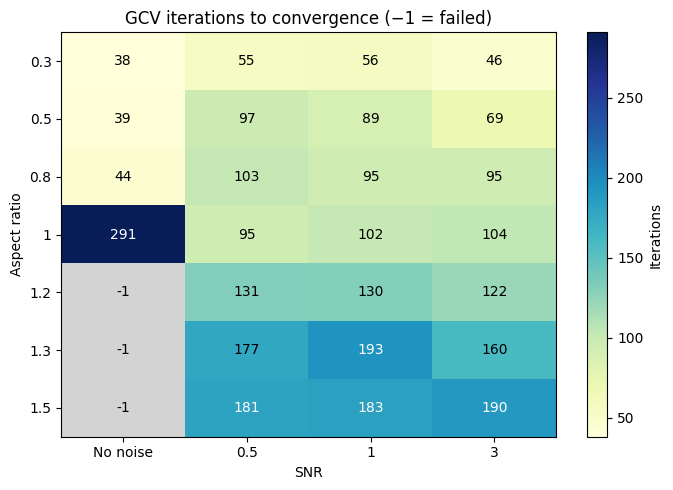

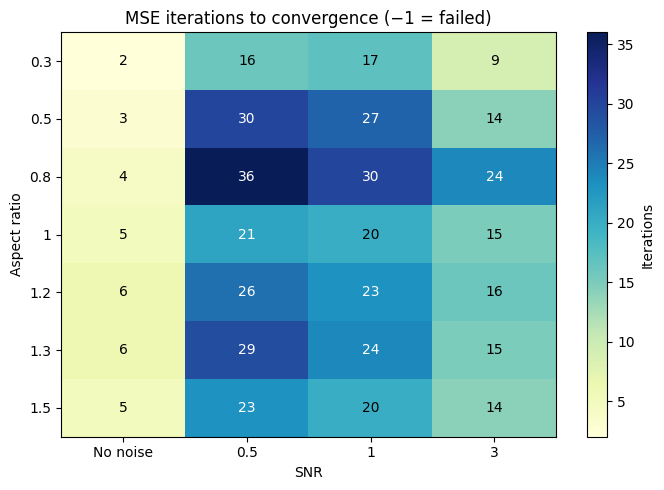

In [19]:
def iteration_table(results, method):
    counts = np.array([
        [results[(ar, snr)][method]["n_iter"]
         for snr in SIGNAL_NOISE_RATIOS]
        for ar in ASPECT_RATIOS
    ])

    # Mask failures so they appear gray.
    values = np.ma.masked_where(counts == -1, counts)
    cmap = plt.get_cmap("YlGnBu").copy()
    cmap.set_bad("lightgray")

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(values, cmap=cmap, aspect="auto")

    ax.set_xticks(
        range(len(SIGNAL_NOISE_RATIOS)),
        labels=["No noise" if snr == 0 else f"{snr:g}"
                for snr in SIGNAL_NOISE_RATIOS],
    )
    ax.set_yticks(
        range(len(ASPECT_RATIOS)),
        labels=[f"{ar:g}" for ar in ASPECT_RATIOS],
    )

    for i in range(counts.shape[0]):
        for j in range(counts.shape[1]):
            count = counts[i, j]
            color = (
                "white"
                if count != -1 and im.norm(count) > 0.55
                else "black"
            )
            ax.text(j, i, str(count), ha="center", va="center", color=color)

    ax.set(
        xlabel="SNR",
        ylabel="Aspect ratio",
        title=f"{method.upper()} iterations to convergence (−1 = failed)",
    )

    if np.any(counts != -1):
        fig.colorbar(im, ax=ax, label="Iterations")

    plt.tight_layout()
    plt.show()


iteration_table(results, "gcv")
iteration_table(results, "mse")

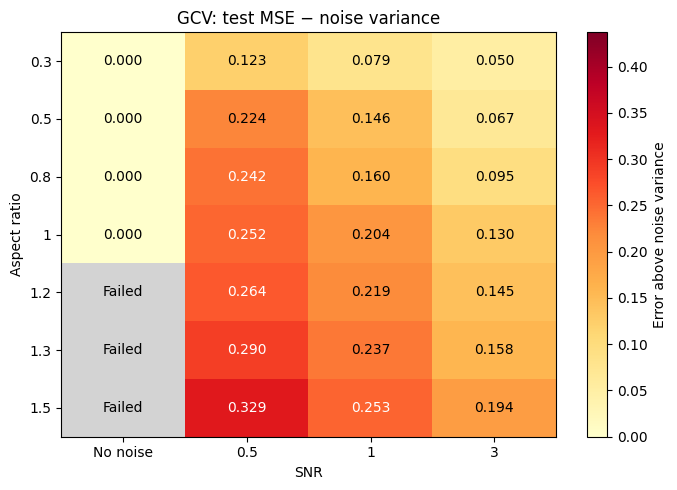

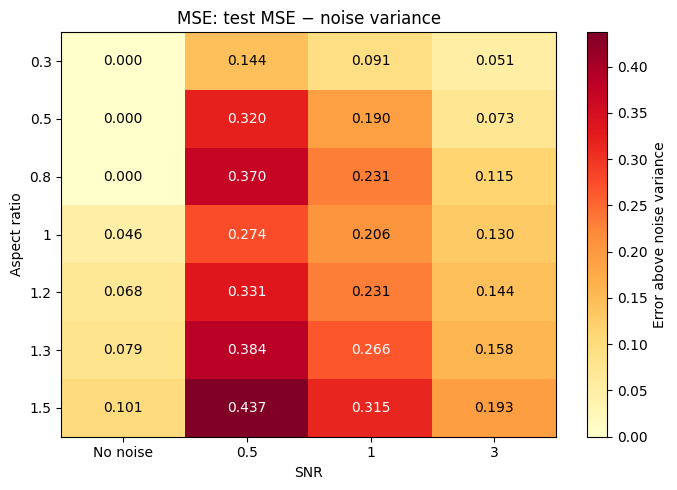

In [20]:
def mse_heatmap(results, method):
    gaps = np.array([
        [
            results[(ar, snr)][method]["test_mse"]
            - results[(ar, snr)]["noise_variance"]
            for snr in SIGNAL_NOISE_RATIOS
        ]
        for ar in ASPECT_RATIOS
    ])

    failed = np.array([
        [not results[(ar, snr)][method]["converged"]
         for snr in SIGNAL_NOISE_RATIOS]
        for ar in ASPECT_RATIOS
    ])

    values = np.ma.masked_where(failed | ~np.isfinite(gaps), gaps)

    # Shared color scale across both methods for easier comparison.
    all_gaps = [
        case[m]["test_mse"] - case["noise_variance"]
        for ar in ASPECT_RATIOS
        for snr in SIGNAL_NOISE_RATIOS
        for case in [results[(ar, snr)]]
        for m in ["gcv", "mse"]
        if case[m]["converged"]
        and np.isfinite(case[m]["test_mse"] - case["noise_variance"])
    ]

    vmin = min(0.0, min(all_gaps)) if all_gaps else 0.0
    vmax = max(0.0, max(all_gaps)) if all_gaps else 1.0
    if vmax == vmin:
        vmax = vmin + 1e-6

    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("lightgray")

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(
        values, cmap=cmap, aspect="auto",
        vmin=vmin, vmax=vmax,
    )

    ax.set_xticks(
        range(len(SIGNAL_NOISE_RATIOS)),
        labels=["No noise" if snr == 0 else f"{snr:g}"
                for snr in SIGNAL_NOISE_RATIOS],
    )
    ax.set_yticks(
        range(len(ASPECT_RATIOS)),
        labels=[f"{ar:g}" for ar in ASPECT_RATIOS],
    )

    for i in range(gaps.shape[0]):
        for j in range(gaps.shape[1]):
            if failed[i, j]:
                label, color = "Failed", "black"
            elif not np.isfinite(gaps[i, j]):
                label, color = "NA", "black"
            else:
                label = f"{gaps[i, j]:.3f}"
                color = "white" if im.norm(gaps[i, j]) > 0.55 else "black"

            ax.text(j, i, label, ha="center", va="center", color=color)

    ax.set(
        xlabel="SNR",
        ylabel="Aspect ratio",
        title=f"{method.upper()}: test MSE − noise variance",
    )

    if values.count() > 0:
        fig.colorbar(im, ax=ax, label="Error above noise variance")

    plt.tight_layout()
    plt.show()


mse_heatmap(results, "gcv")
mse_heatmap(results, "mse")

In [25]:
# Edit ASPECT_RATIO and SIGNAL_NOISE here, then rerun this cell and the plot cell only.
ASPECT_RATIO = 0.8
SIGNAL_NOISE = 0.5
selected_case = results[(ASPECT_RATIO, SIGNAL_NOISE)]
for method in ["gcv", "mse"]:
    result = selected_case[method]
    print(f"{method.upper()}: n_iter={result['n_iter']}, "
          f"steps_completed={result['steps_completed']}, status={result['status']}, "
          f"lambda={result['lambda_star']:.6g}, test MSE={result['test_mse']:.6g}")
    if result.get("message"):
        print("  ", result["message"])

GCV: n_iter=103, steps_completed=103, status=converged, lambda=675.015, test MSE=1.14721
MSE: n_iter=36, steps_completed=36, status=converged, lambda=131.119, test MSE=1.27538


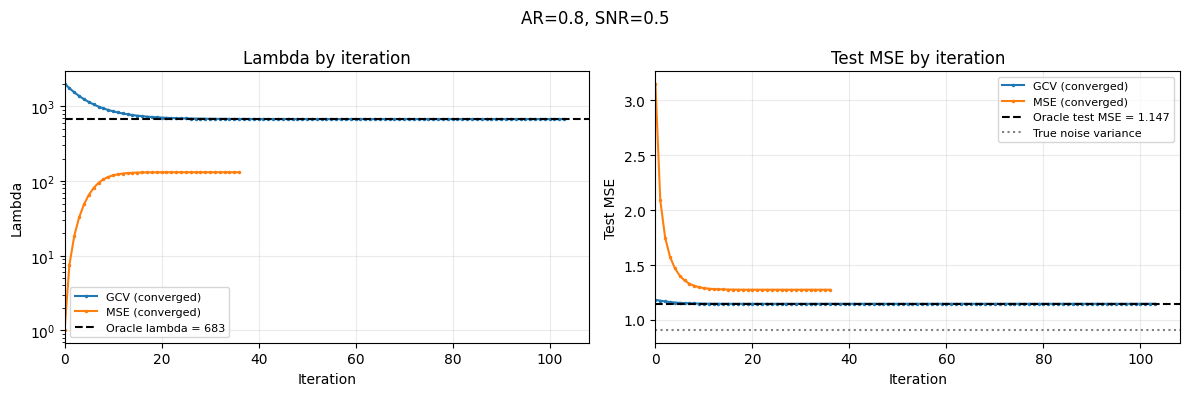

In [29]:
def plot_case(results, aspect_ratio, signal_noise):
    case = results[(float(aspect_ratio), float(signal_noise))]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    for method, color in [("gcv", "tab:blue"), ("mse", "tab:orange")]:
        result = case[method]
        h = result["history"]

        if not len(h["lambda"]):
            continue

        style = dict(
            color=color,
            label=f"{method.upper()} ({result['status']})",
            marker=".",
            markersize=3,
        )

        # Left: lambda by iteration
        axes[0].plot(h["iteration"], h["lambda"], **style)

        # Right: test MSE by iteration
        axes[1].plot(h["iteration"], h["test_mse"], **style)

    optimal_lambda = case["mse"]["oracle"]["lambda"]

    if np.isfinite(optimal_lambda) and optimal_lambda > 0:
      axes[0].axhline(
          optimal_lambda,
          color="black",
          linestyle="--",
          label=f"Oracle lambda = {optimal_lambda:.4g}",
      )

    oracle_test_mse = case["mse"].get("oracle", {}).get("test_mse", np.nan)

    if np.isfinite(oracle_test_mse):
        axes[1].axhline(
            oracle_test_mse,
            color="black",
            linestyle="--",
            label=f"Oracle test MSE = {oracle_test_mse:.4g}",
        )

    axes[0].set(
        title="Lambda by iteration",
        xlabel="Iteration",
        ylabel="Lambda",
        yscale="log",
    )

    axes[1].set(
        title="Test MSE by iteration",
        xlabel="Iteration",
        ylabel="Test MSE",
    )
    axes[1].axhline(
        case["noise_variance"],
        color="gray",
        linestyle=":",
        label="True noise variance",
    )

    for ax in axes:
        ax.set_xlim(left=0)
        ax.grid(alpha=0.25)
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)

    snr_label = "No noise" if signal_noise == 0 else f"SNR={signal_noise:g}"
    fig.suptitle(f"AR={aspect_ratio:g}, {snr_label}")
    plt.tight_layout()
    plt.show()


plot_case(results, ASPECT_RATIO, SIGNAL_NOISE)

In [23]:
case = results[(ASPECT_RATIO, SIGNAL_NOISE)]

print("Noise variance:", case["noise_variance"])
print("Predicting zero:", case["zero_prediction_test_mse"])
print("GCV test MSE:", case["gcv"]["test_mse"])
print("MSE procedure test MSE:", case["mse"]["test_mse"])

Noise variance: 0.13322695332041304
Predicting zero: 0.518887675963592
GCV test MSE: 0.2277280102828086
MSE procedure test MSE: 0.2483831009406952


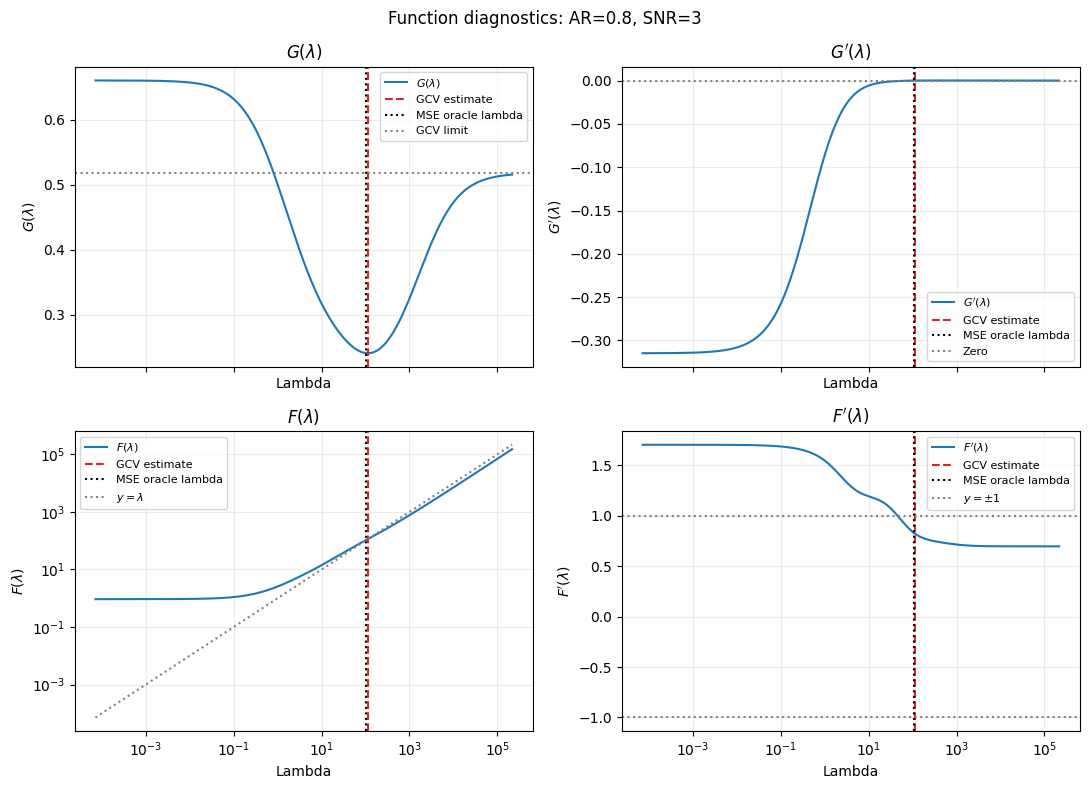

In [24]:
def plot_function_displays(results, aspect_ratio, signal_noise, points=1000):
    case = results[(float(aspect_ratio), float(signal_noise))]
    n, d = case["n"], case["d"]

    # Reconstruct the same training data used by run_case.
    seed_sequence = np.random.SeedSequence([
        case["seed"],
        int(round(aspect_ratio * 1000000)),
        int(round(signal_noise * 1000000)),
    ])
    train_seed, _ = seed_sequence.spawn(2)
    rng = np.random.default_rng(train_seed)

    covariance = spiked_covariance(d)

    theta = rng.standard_normal((d, 1))
    theta /= np.linalg.norm(theta)

    epsilon = (
        0.0 if signal_noise == 0
        else np.sqrt(
            (theta.T @ covariance @ theta).item() / signal_noise
        )
    )

    X = generate_X(n, d, covariance, rng)
    y = generate_Y(X, n, theta, epsilon, rng)

    U, sigma, _ = np.linalg.svd(X, full_matrices=True)
    a = U.T @ y

    # Positive lambda range; exclude numerically zero singular values.
    threshold = np.finfo(float).eps * max(n, d) * sigma.max()
    positive_sigma = sigma[sigma > threshold]

    lam_min = positive_sigma.min() ** 2 * 1e-4
    lam_max = sigma.max() ** 2 * 1e2

    gcv_lambda = case["gcv"]["lambda_star"]
    oracle_lambda = case["mse"].get("oracle", {}).get("lambda", np.nan)

    # Ensure finite positive reference lambdas are inside the plotting range.
    for lam in [gcv_lambda, oracle_lambda]:
        if np.isfinite(lam) and lam > 0:
            lam_min = min(lam_min, lam / 10)
            lam_max = max(lam_max, lam * 10)

    lam_grid = np.geomspace(lam_min, lam_max, points)

    def evaluate(function):
        values = []
        for lam in lam_grid:
            try:
                with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
                    value = function(lam, n, a, sigma)
                values.append(value if np.isfinite(value) else np.nan)
            except (ZeroDivisionError, FloatingPointError):
                values.append(np.nan)
        return np.asarray(values)

    functions = [
        (G,       r"$G(\lambda)$"),
        (Gprime,  r"$G'(\lambda)$"),
        (F,       r"$F(\lambda)$"),
        (F_prime, r"$F'(\lambda)$"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(11,8), sharex=True)

    for ax, (function, title) in zip(axes.flat, functions):
        ax.plot(lam_grid, evaluate(function), color="tab:blue", label=title)

        if np.isfinite(gcv_lambda) and gcv_lambda > 0:
            label = (
                "GCV estimate" if case["gcv"]["converged"]
                else "GCV last iterate"
            )
            ax.axvline(
                gcv_lambda, color="tab:red", linestyle="--", label=label
            )

        if np.isfinite(oracle_lambda) and oracle_lambda > 0:
            ax.axvline(
                oracle_lambda,
                color="black",
                linestyle=":",
                label="MSE oracle lambda",
            )

        ax.set(title=title, xlabel="Lambda", ylabel=title, xscale="log")
        ax.grid(alpha=0.25)

    # GCV limit as lambda -> infinity.
    axes[0, 0].axhline(
        np.mean(y ** 2),
        color="gray",
        linestyle=":",
        label="GCV limit",
    )

    # Stationary points of G occur where G' = 0.
    axes[0, 1].axhline(0, color="gray", linestyle=":", label="Zero")

    # Fixed points occur where H(lambda) or F(lambda) intersects lambda.
    for ax in [axes[1, 0]]:
        ax.plot(
            lam_grid, lam_grid,
            color="gray", linestyle=":", label=r"$y=\lambda$"
        )
        ax.set_yscale("log")

    # Derivative thresholds for contraction.
    for ax in [axes[1, 1]]:
        ax.axhline(1, color="gray", linestyle=":", label=r"$y=\pm1$")
        ax.axhline(-1, color="gray", linestyle=":")

    for ax in axes.flat:
        ax.legend(fontsize=8)

    snr_label = "No noise" if signal_noise == 0 else f"SNR={signal_noise:g}"
    fig.suptitle(f"Function diagnostics: AR={aspect_ratio:g}, {snr_label}")
    plt.tight_layout()
    plt.show()


plot_function_displays(results, ASPECT_RATIO, SIGNAL_NOISE)